# Forecast ensemble performance and initial shock

## Purpose

Two figures for the hindcasts, each in its own section:

- **Daily performance** (section 3, main manuscript figure): daily ensemble-mean RMSE and spread/error consistency of PSL, TREFHT, PRECT, and FLUT for every experiment, plus bias and fair CRPS; for the larger ensembles the RMSE panels also show 10-member subsets, so every experiment is compared at the same ensemble size.
- **Field time series** (section 3): the regional-mean daily TREFHT, PRECT, and FLUT, S0 and S1 in one figure, ensemble mean and member range of each experiment against the observations (black).
- **Initial shock** (section 4, validation / supplement): the native 6-hourly adjustment right after initialization for the same variables (PSL, TREFHT, PRECT, FLUT): regional mean $|dX/dt|$ and $|dX/dt|$ normalized by its settled level, with the reference tendency.

The comparisons to keep in view are CTRL10 → CAPT10 → DART10 (initialization strategy at equal ensemble size) and DART10 → DART20 → DART40 (ensemble size; the subset test separates the effect of averaging more members).

## Inputs

6-hourly member output `ts/6hourly/<variable>.EN##.<year>.nc` of the hindcasts registered in `util/bias_metrics.py`, and references under `OBSERVATION_ROOT`: ERA5 6-hourly (PSL, TREFHT; PRECT in the shock section), GPCP daily (PRECT; GPM IMERG and ERA5 are available as sensitivity choices), NOAA interpolated OLR daily (FLUT).

## Processing

**Daily performance: 6-hourly member fields → daily member fields → ensemble diagnostics.** Each member is first aggregated to 24-hour forecast-lead bins (day $k$ covers lead hours $(24(k-1), 24k]$; independent of the start hour): PSL, stored as instantaneous values, by a time-weighted (trapezoid) mean of the 0, 6, 12, 18, and 24 h states; TREFHT, PRECT (a rate, kept as mm day$^{-1}$), and FLUT, stored as 6-hour interval means, by the mean of the four intervals. Day 1 is the first complete 24-hour interval, and the lead-0 snapshot never enters an interval-mean variable. The stored temporal semantics are checked before processing. The references are averaged over the same bins. Ensemble mean, spread, bias, RMSE, and fair CRPS are then computed from the daily fields, on the same gridpoints and cos-latitude weights for every metric (the region intersected with the reference coverage).

**Initial shock:** native 6-hourly regional diagnostics (see Notes), with its own variables and windows.

## Outputs

Daily metrics caches (`daily_skill/`), shock caches, and summary CSVs under `DIAGNOSTIC_OUTPUT_ROOT/data/fcst_atm_ensemble_ts/`; PDF figures (`FIGURE_FORMAT` in each figure cell) under `DIAGNOSTIC_OUTPUT_ROOT/figure/fcst_atm_ensemble_ts/daily_performance/` and `.../shock/`. Review the user setup, then run the notebook from top to bottom; each section can also be rerun on its own after the shared setup.

## 1. Libraries

In [1]:
# Pick up edits to util/ modules without restarting the kernel.
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## 2. User setup

Paths; the season, experiments, and regions (shared by both figures); then the settings of each figure; and run options. Edit this cell for normal changes.


In [2]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")  # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")  # land mask
WORKFLOW_NAME = "fcst_atm_ensemble_ts"

# What to compare
# Season -> experiments; one figure per season (and region). Remove a season to skip it.
CASES = {
    "S0": ("CTRL10-S0", "CAPT10-S0", "DART10-S0", "DART20-S0", "DART40-S0"),  # Jan-Feb 2012
    "S1": ("CTRL10-S1", "CAPT10-S1", "DART40-S1"),  # Jun-Jul 2012
}
# global, 60S-60N (common domain if PRECT uses GPM), land, ocean, Tropics,
# CONUS, NHMidLat, NINO3.4, MAR_CONT; one figure per region
REGIONS = ("global",)

# ---- Daily performance (section 3) ----
DAILY = dict(
    variables=("PSL", "TREFHT", "PRECT", "FLUT"),
    references={"PRECT": "GPCP"},  # PRECT sensitivity: "GPM" (60S-60N only), "ERA5"
    max_day=30,  # forecast days shown in the figure
    n_subsets=100,  # random subsets for ensembles larger than subset_size
    subset_size=10,
    seed=42,
    baselines=("CTRL10", "CAPT10"),  # % RMSE changes in the summary table
)

# ---- Initial shock (section 4; native 6-hourly output) ----
SHOCK = dict(
    frequency="6hourly",
    variables=DAILY["variables"],  # same variables as the daily performance figure
    core=("CTRL10", "CAPT10", "DART10"),  # solid; other experiments dashed (sensitivity)
    zoom_days=30,  # lead days shown
    plots=("tendency",),  # add "timeseries" for member time series
)
SHOCK_DAYS = 2.0  # window treated as the initial shock (lead days)
SETTLED_DAYS = (10.0, 30.0)  # window taken as the adjusted state
TOLERANCE = 0.2  # adjustment lasts while the 1-day running |dX/dt| exceeds (1 + TOLERANCE) x settled

VALIDATE_SEMANTICS = True  # check stored time semantics and the daily aggregation once
MAX_MEMBERS = None  # e.g. 2 for a quick test (no subsets then); caches record the ensemble size
FORCE_COMPUTE = False
SHOW = True  # figure settings (font size, title, dpi) are at the top of each figure cell

## 3. Shared setup

Paths, experiments, and labels used by both sections.


In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.bias_metrics import experiment_registry
from util.forecast_ensemble_ts import validate_regions

validate_regions(REGIONS)
data_dir, figure_root = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)
cases = {season: tuple(experiments) for season, experiments in CASES.items()}
registries = {season: experiment_registry(INPUT_DATA_ROOT, season, "fc") for season in cases}
for season, experiments in cases.items():
    unknown = set(experiments) - set(registries[season])
    if unknown:
        raise ValueError(f"{season}: {sorted(unknown)} unavailable; choose from {list(registries[season])}")
    print(f"{season} {list(experiments)} | regions {list(REGIONS)}")
labels = {name: registries[season][name]["label"] for season, experiments in cases.items() for name in experiments}

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


S0 ['CTRL10-S0', 'CAPT10-S0', 'DART10-S0', 'DART20-S0', 'DART40-S0'] | regions ['global']
S1 ['CTRL10-S1', 'CAPT10-S1', 'DART40-S1'] | regions ['global']


## 4. Daily performance

### Driver: validate, read, process, and save data

Check the stored time semantics, reuse valid caches or build missing ones, then compute and save the summary table.


In [4]:
from util.forecast_daily_skill import (
    check_temporal_semantics, daily_skill_summary, read_or_process_daily_skill,
    validate_daily_aggregation, validate_daily_mode,
)

daily = validate_daily_mode("daily_performance", {"daily_performance": DAILY})
print(f"daily performance: {daily}")
if VALIDATE_SEMANTICS:  # first experiment of each season
    for season, experiments in cases.items():
        first = registries[season][experiments[0]]
        display(check_temporal_semantics(first, daily["variables"], first["period"]))
        display(pd.DataFrame([validate_daily_aggregation(first, v, first["period"]) for v in daily["variables"]]))

daily_results, registries, failures = read_or_process_daily_skill(
    cases, daily["variables"], data_root=INPUT_DATA_ROOT, reference_root=OBSERVATION_ROOT,
    cache_dir=data_dir, regions=REGIONS, landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc",
    references=daily["references"], max_members=MAX_MEMBERS, n_subsets=daily["n_subsets"],
    subset_size=daily["subset_size"], seed=daily["seed"], force_compute=FORCE_COMPUTE,
)
for season, variable, experiment, error in failures:
    print(f"[SKIPPED] {season} {variable} {experiment}: {error}")
daily_summary = daily_skill_summary(daily_results, baselines=daily["baselines"])
for season in cases:
    table_path = data_dir / f"summary_{season}_fc_daily_performance.csv"
    daily_summary[daily_summary["season"] == season].to_csv(table_path, index=False)
    print(f"[TABLE] {table_path}")


daily performance: {'references': {'PRECT': 'GPCP'}, 'max_day': 30, 'n_subsets': 100, 'subset_size': 10, 'seed': 42, 'baselines': ('CTRL10', 'CAPT10'), 'variables': ('PSL', 'TREFHT', 'PRECT', 'FLUT')}


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,PRECT,time: mean,m/s,0.0,6.0,width-weighted mean of interval means,ok
3,FLUT,time: mean,W/m2,0.0,6.0,width-weighted mean of interval means,ok


,variable,stored_daily_file,daily_file_cell_methods,comparison,max_abs_difference,mean_abs_difference,mean_abs_value
0,PSL,ts/daily_mean,time: mean (00Z to 24Z of the day) (average of...,compared,6.068932,5.404141e-01,1008.316675
1,TREFHT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000031,8.921250e-06,278.162845
2,PRECT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000027,1.100693e-07,2.444765
3,FLUT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,5.052343,1.397050e-01,225.003118


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,PRECT,time: mean,m/s,0.0,6.0,width-weighted mean of interval means,ok
3,FLUT,time: mean,W/m2,0.0,6.0,width-weighted mean of interval means,ok


,variable,stored_daily_file,daily_file_cell_methods,comparison,max_abs_difference,mean_abs_difference,mean_abs_value
0,PSL,ts/daily_mean,time: mean (00Z to 24Z of the day) (average of...,compared,4.947838,5.728536e-01,1008.684324
1,TREFHT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000031,9.101389e-06,280.248818
2,PRECT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,0.000012,1.095454e-07,2.426881
3,FLUT,ts/daily_mean,time: mean (00Z to 24Z of the day),compared,5.019867,1.609575e-01,223.847426


[REUSE] CTRL10-S0_PSL_201201-201202_daily_skill.nc
[REUSE] CAPT10-S0_PSL_201201-201202_daily_skill.nc
[REUSE] DART10-S0_PSL_201201-201202_daily_skill.nc
[REUSE] DART20-S0_PSL_201201-201202_daily_skill.nc
[REUSE] DART40-S0_PSL_201201-201202_daily_skill.nc
[REUSE] CTRL10-S0_TREFHT_201201-201202_daily_skill.nc
[REUSE] CAPT10-S0_TREFHT_201201-201202_daily_skill.nc
[REUSE] DART10-S0_TREFHT_201201-201202_daily_skill.nc
[REUSE] DART20-S0_TREFHT_201201-201202_daily_skill.nc
[REUSE] DART40-S0_TREFHT_201201-201202_daily_skill.nc
[REUSE] CTRL10-S0_PRECT_201201-201202_daily_skill.nc
[REUSE] CAPT10-S0_PRECT_201201-201202_daily_skill.nc
[REUSE] DART10-S0_PRECT_201201-201202_daily_skill.nc
[REUSE] DART20-S0_PRECT_201201-201202_daily_skill.nc
[REUSE] DART40-S0_PRECT_201201-201202_daily_skill.nc
[REUSE] CTRL10-S0_FLUT_201201-201202_daily_skill.nc
[REUSE] CAPT10-S0_FLUT_201201-201202_daily_skill.nc
[REUSE] DART10-S0_FLUT_201201-201202_daily_skill.nc
[REUSE] DART20-S0_FLUT_201201-201202_daily_skill.nc
[R

### Figures

Two figures, each one row per variable (`PERF_VARIABLES`: TREFHT, PRECT, FLUT, as in the field time series) and one column per season (S0 / January left, S1 / June right): the daily ensemble-mean RMSE, with the 10-member subsets of the larger ensembles, and the spread/RMSE ratio. Panels are labelled "(a) TREFHT (January)", "(b) TREFHT (June)", ...; the details are printed and saved as each figure's caption (`<figure>.caption.txt`). Colors by experiment type and markers by season (S0 circles, S1 squares); the legend lists every experiment, one row per season, as in the field time series below.

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/daily_performance/fig_daily_rmse_global_S0_S1_fc.pdf
[CAPTION] Root-mean-square error (RMSE) of the daily ensemble mean against observations for (a, b) 2-m air temperature (TREFHT; K), (c, d) precipitation (PRECT; mm day⁻¹), and (e, f) outgoing longwave radiation at the top of the atmosphere (FLUT; W m⁻²), global mean, in forecast days 1-30 of the S0 (boreal winter) hindcasts initialized at 00 UTC 1 January 2012 (left column) and S1 (boreal summer) hindcasts initialized at 00 UTC 1 June 2012 (right column). Lines show CTRL10 (gray), CAPT10 (blue), DART10 (green), DART20 (orange), and DART40 (red); the number is the ensemble size. DART10 and DART20 were run for S0 only. S0 experiments are marked with circles and S1 experiments are marked with squares. For DART20 and DART40, dashed lines and shading give the mean and 5-95% range of the RMSE of 100 randomly drawn 10-member subsets, for comparison at equal e

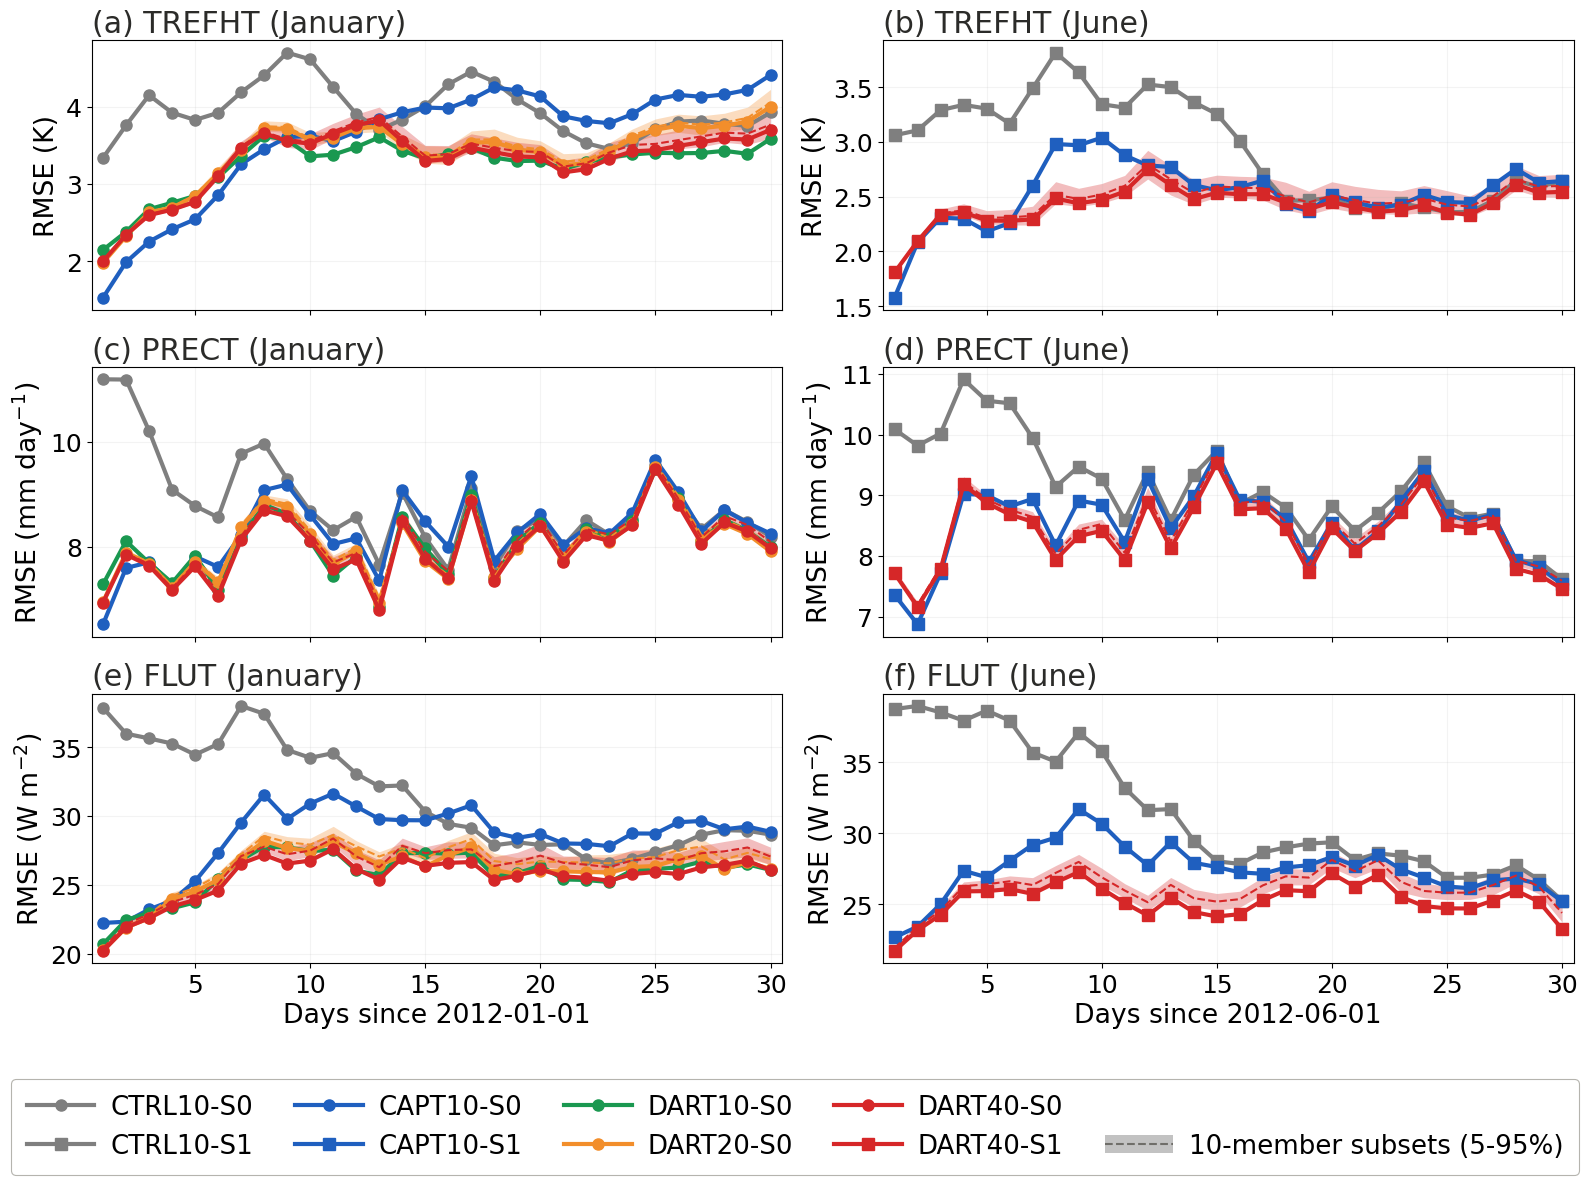

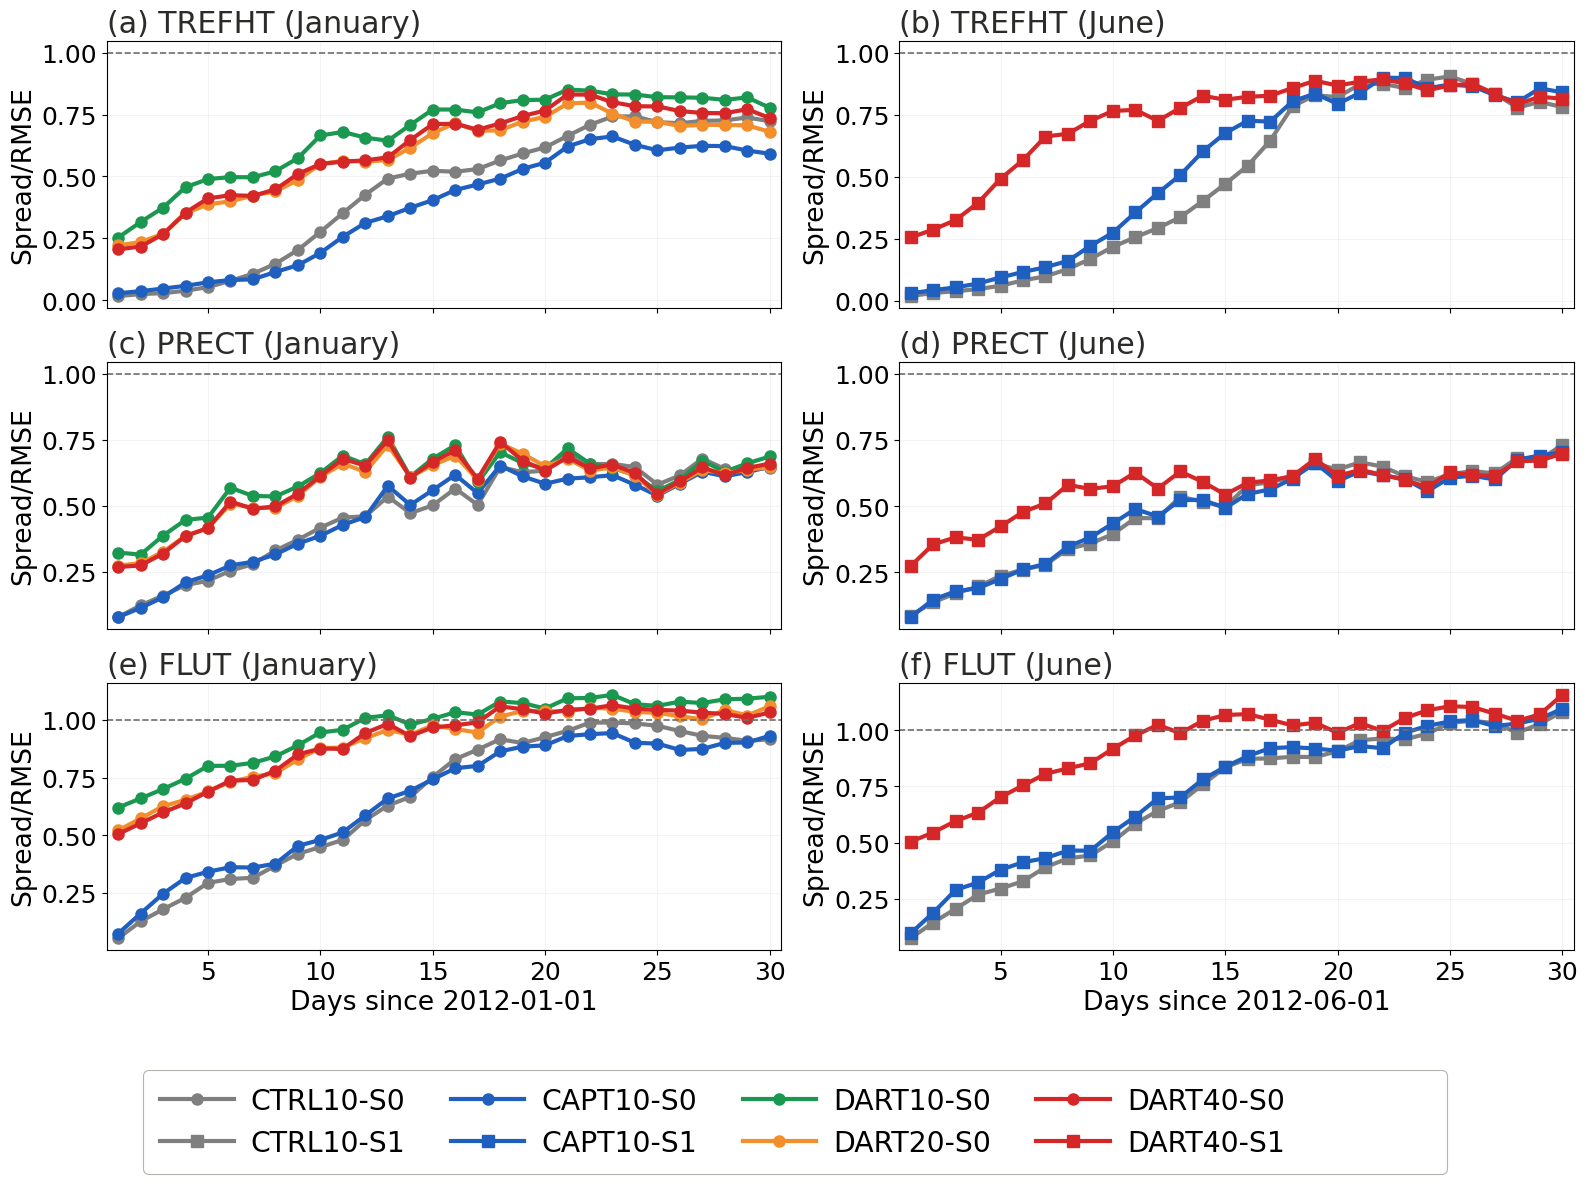

In [5]:
from util.forecast_daily_skill import DAILY_METRIC_NAMES, plot_daily_metric, results_colors

def listing(items):  # "a, b, and c"
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + (", and " if len(items) > 2 else " and ") + items[-1]

# ---- Figure settings ----
FONTZ = 24  # base font size (as in the field time series); panel titles 0.9x, axis labels 0.8x, ticks 0.75x, legend 0.85x, title 1x
FIGURE_TITLE = False  # False: no title above the panels (details go in the caption)
FIGURE_FORMAT = "pdf"  # "pdf" (vector) or "png"
FIGURE_DPI = 600  # png, and shaded areas inside the pdf

MAX_DAY = daily["max_day"]  # forecast days shown
PERF_VARIABLES = ("TREFHT", "PRECT", "FLUT")  # rows (any of DAILY["variables"]); same as the field time series
METRICS = ("rmse", "spread_ratio")  # one figure each: Ensemble-Mean RMSE, Spread/RMSE
PERF_SEASONS = tuple(CASES)  # columns (S0 / January left, S1 / June right)
PERF_SEASON_NAMES = None  # panel labels "(a) TREFHT (January)"; None: month of each initial date; or {"S0": "...", "S1": "..."}
PANEL_SIZE = (8.0, 4.0)  # (width, height) of one panel, inches (as in the field time series)

XLABEL = None  # None: "Days since <initial date>" under each season column; or any text, e.g. "Forecast day"
# Experiment lines: colors by experiment type, markers by season (as in the field time series)
# Colors by experiment type (any season); types not listed keep the shared categorical colors
COLORS = {"CTRL10": "#7f7f7f",  # gray
          "CAPT10": "#1f5fbf",  # blue
          "DART10": "#1a9850",  # green
          "DART20": "#f28e2b",  # orange
          "DART40": "#d62728"}  # red

LINE_WIDTH = 3.0
LINE_STYLES = {}  # per-experiment override, e.g. {"DART20-S0": "--"}; default solid "-"
PERF_MARKERS = {"S0": "o", "S1": "s"}  # by season (S0 circles, S1 squares); seasons not listed use MARKER
MARKER = "o"  # seasons not in PERF_MARKERS; None: no markers
MARKERS = {}  # per-experiment override, e.g. {"CAPT10-S0": "D"}
MARKER_SIZE = 8

# 10-member subsets (RMSE figure, larger ensembles)
SUBSET_LINE_WIDTH = 1.5
SUBSET_LINE_STYLE = "--"
SUBSET_ALPHA = 0.30  # 5-95% shading; 0: no shading

# Other lines
REFERENCE_LINE = dict(color="#6f6e69", lw=1.2, ls="--")  # spread/RMSE = 1
GRID_ALPHA = 0.15  # 0: no grid
# Legend (below the panels, as in the field time series)
LEGEND_FRAME = True  # rounded box around the legend
LEGEND_BY = "experiment"  # "experiment": CTRL10-S0, ..., one row per season; "type": CTRL10, ... once
LEGEND_NCOL = 5 #None  # None: one column per experiment type (S1 under S0, two rows); a number overrides it
LEGEND_EDGECOLOR = "#b5b4ae"

# Caption pieces shared by both figures.
names = {"PSL": "sea-level pressure (PSL; hPa)", "TREFHT": "2-m air temperature (TREFHT; K)",
         "PRECT": "precipitation (PRECT; mm day⁻¹)",
         "FLUT": "outgoing longwave radiation at the top of the atmosphere (FLUT; W m⁻²)"}

color_names = {"#7f7f7f": "gray", "#1f5fbf": "blue", "#1a9850": "green", "#f28e2b": "orange",
               "#d62728": "red", "#000000": "black", "#8b0000": "dark red"}

marker_names = {"o": "circles", "s": "squares", "^": "triangles", "D": "diamonds", "v": "inverted triangles"}
line_names = {"-": "solid", "--": "dashed", ":": "dotted", "-.": "dash-dot"}

figure_dir = figure_root / "daily_performance"
figure_dir.mkdir(parents=True, exist_ok=True)

kind = lambda experiment: experiment.split("-")[0]  # DART20-S0 -> DART20
colors = results_colors(daily_results)
colors.update({e: COLORS[kind(e)] for e in colors if kind(e) in COLORS})
season_of = lambda experiment: experiment.rsplit("-", 1)[-1]  # DART20-S0 -> S0
markers = {e: PERF_MARKERS[season_of(e)] for e in colors if season_of(e) in PERF_MARKERS}
markers.update(MARKERS)

variables = [v for v in PERF_VARIABLES if any(v in daily_results[s] for s in PERF_SEASONS)]
starts = {s: pd.Timestamp(next(iter(next(iter(daily_results[s].values())).values())).day_start.values[0])
          for s in PERF_SEASONS}

first = next(iter(next(iter(daily_results[PERF_SEASONS[0]].values())).values()))
experiments = [e for s in PERF_SEASONS for e in next(iter(daily_results[s].values()))]
types = list(dict.fromkeys(kind(e) for e in experiments))
first_of = {t_: next(e for e in experiments if kind(e) == t_) for t_ in types}
present = {s: {kind(e) for e in next(iter(daily_results[s].values()))} for s in PERF_SEASONS}
only = {s: [t_ for t_ in types if t_ in present[s] and all(t_ not in present[o] for o in PERF_SEASONS if o != s)]
        for s in PERF_SEASONS} if len(PERF_SEASONS) > 1 else {s: [] for s in PERF_SEASONS}
larger = list(dict.fromkeys(kind(e) for s in PERF_SEASONS for e, ds in next(iter(daily_results[s].values())).items()
                            if "rmse_subset" in ds))
refs = {v: next(iter(daily_results[PERF_SEASONS[0]][v].values())).attrs.get("reference", "") for v in variables}
by_product = {}

for v, product in refs.items():
    by_product.setdefault({"GPCP": "GPCP daily", "NOAA OLR": "NOAA interpolated OLR"}.get(product, product), []).append(v)

ncol = len(PERF_SEASONS)
def rows_for(metric):  # "(a, b) 2-m air temperature (TREFHT; K), ..."; no units for the ratio
    label = (lambda v: names.get(v, v)) if metric == "rmse" else (lambda v: names.get(v, v).split(";")[0] + ")")
    return listing(f"({', '.join(chr(97 + r * ncol + c) for c in range(ncol))}) {label(v)}"
                   for r, v in enumerate(variables))
columns = listing(f"{s} ({'boreal winter' if s == 'S0' else 'boreal summer'}) hindcasts initialized at "
                  f"{starts[s]:%H} UTC {starts[s].day} {starts[s]:%B %Y}"
                  + (f" ({['left', 'right'][k]} column)" if ncol == 2 else "")
                  for k, s in enumerate(PERF_SEASONS))

for metric, region in ((m, r) for m in METRICS for r in REGIONS):
    fig = plot_daily_metric(
        daily_results, region, metric=metric, labels=labels, colors=colors, variables=PERF_VARIABLES,
        seasons=PERF_SEASONS, max_day=MAX_DAY, fontz=FONTZ,
        title=f"{DAILY_METRIC_NAMES[metric]}, {region}" if FIGURE_TITLE else "", panel_size=PANEL_SIZE,
        line_width=LINE_WIDTH, line_styles=LINE_STYLES, marker=MARKER, markers=markers, marker_size=MARKER_SIZE,
        subset_line_width=SUBSET_LINE_WIDTH, subset_line_style=SUBSET_LINE_STYLE, subset_alpha=SUBSET_ALPHA,
        reference_line=REFERENCE_LINE, grid_alpha=GRID_ALPHA,
        legend_frame=LEGEND_FRAME, legend_ncol=LEGEND_NCOL, legend_edgecolor=LEGEND_EDGECOLOR,
        xlabel=XLABEL, season_names=PERF_SEASON_NAMES, legend_by=LEGEND_BY,
    )
    output = figure_dir / f"fig_daily_{metric}_{region}_{'_'.join(PERF_SEASONS)}_fc.{FIGURE_FORMAT}"
    fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {output}")
    # Manuscript caption, built from the data and the settings above; saved next to the figure.
    what = ("Root-mean-square error (RMSE) of the daily ensemble mean against observations"
            if metric == "rmse" else
            "Ratio of the ensemble spread to the ensemble-mean RMSE, with the spread adjusted for finite "
            "ensemble size N by sqrt((N+1)/N),")
    caption = (
        f"{what} for {rows_for(metric)}, {'global' if region == 'global' else region} mean, in forecast days 1-{MAX_DAY} "
        f"of the {columns}. "
        + (f"A ratio of 1 ({line_names.get(REFERENCE_LINE.get('ls', '--'), 'horizontal')} line) indicates a "
           "statistically consistent ensemble, and values below 1 an underdispersive one. "
           if metric == "spread_ratio" else "")
        + "Lines show "
        + listing(f"{t_} ({color_names.get(colors[first_of[t_]].lower(), colors[first_of[t_]])})" for t_ in types)
        + "; the number in each name is the ensemble size. "
        + "".join(f"{listing(only[s])} {'was' if len(only[s]) == 1 else 'were'} run for {s} only. "
                  for s in PERF_SEASONS if only[s])
        + (listing(f"{s} experiments are marked with {marker_names.get(PERF_MARKERS.get(s, MARKER), 'markers')}"
                   for s in PERF_SEASONS) + ". "
           if len(set(PERF_MARKERS.get(s, MARKER) for s in PERF_SEASONS)) > 1 else "")
        + (f"For {' and '.join(larger)}, {line_names.get(SUBSET_LINE_STYLE, 'thin')} lines"
           + (" and shading" if SUBSET_ALPHA else "")
           + f" give the mean{' and 5-95% range' if SUBSET_ALPHA else ''} of the RMSE of "
           f"{first.attrs.get('n_subsets')} randomly drawn {first.attrs.get('subset_size')}-member subsets, "
           "for comparison at equal ensemble size. " if metric == "rmse" and larger else "")
        + "Day k is the 24-h mean ending k days after initialization, computed from the 6-hourly model output; "
        f"{'errors are' if metric == 'rmse' else 'errors and spread are'} area-weighted (cosine of latitude) over the {'globe' if region == 'global' else region} "
        "on the 1 x 1 degree grid. "
        "References: " + "; ".join(f"{p} ({', '.join(vs)})" for p, vs in by_product.items()) + "."
    )
    output.with_suffix(".caption.txt").write_text(caption + "\n")
    print("[CAPTION]", caption)
    if not SHOW:
        plt.close(fig)

### Field time series

Regional-mean daily TREFHT, PRECT, and FLUT (`TS_VARIABLES`), one row per variable and one column per season (S0 left, S1 right): the ensemble mean of each experiment (shading: member range) and, with `SHOW_OBS = True`, the observations (black), on the same forecast-lead days, gridpoints, and references as the performance figure above. Colors by experiment type (`TS_COLORS`, the performance figure's `COLORS` by default), markers by season (`TS_MARKERS`: S0 circles, S1 squares).

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/daily_performance/fig_daily_timeseries_global_S0_S1_fc.pdf
[CAPTION] Global-mean daily (a, b) 2-m air temperature (TREFHT; K), (c, d) precipitation (PRECT; mm day⁻¹), and (e, f) outgoing longwave radiation at the top of the atmosphere (FLUT; W m⁻²) in the first 30 forecast days of the S0 hindcasts initialized at 00 UTC 1 January 2012 (left column) and S1 hindcasts initialized at 00 UTC 1 June 2012 (right column). Lines show the ensemble mean of CTRL10 (gray), CAPT10 (blue), DART10 (green), DART20 (orange), and DART40 (red); the number is the ensemble size. DART10 and DART20 were run for S0 only. S0 experiments are marked with circles and S1 experiments are marked with squares. Shading spans the range (minimum to maximum) of the individual members' global means. Day k is the 24-h mean ending k days after initialization, computed from the 6-hourly model output; global means are area-weighted (cosine of lat

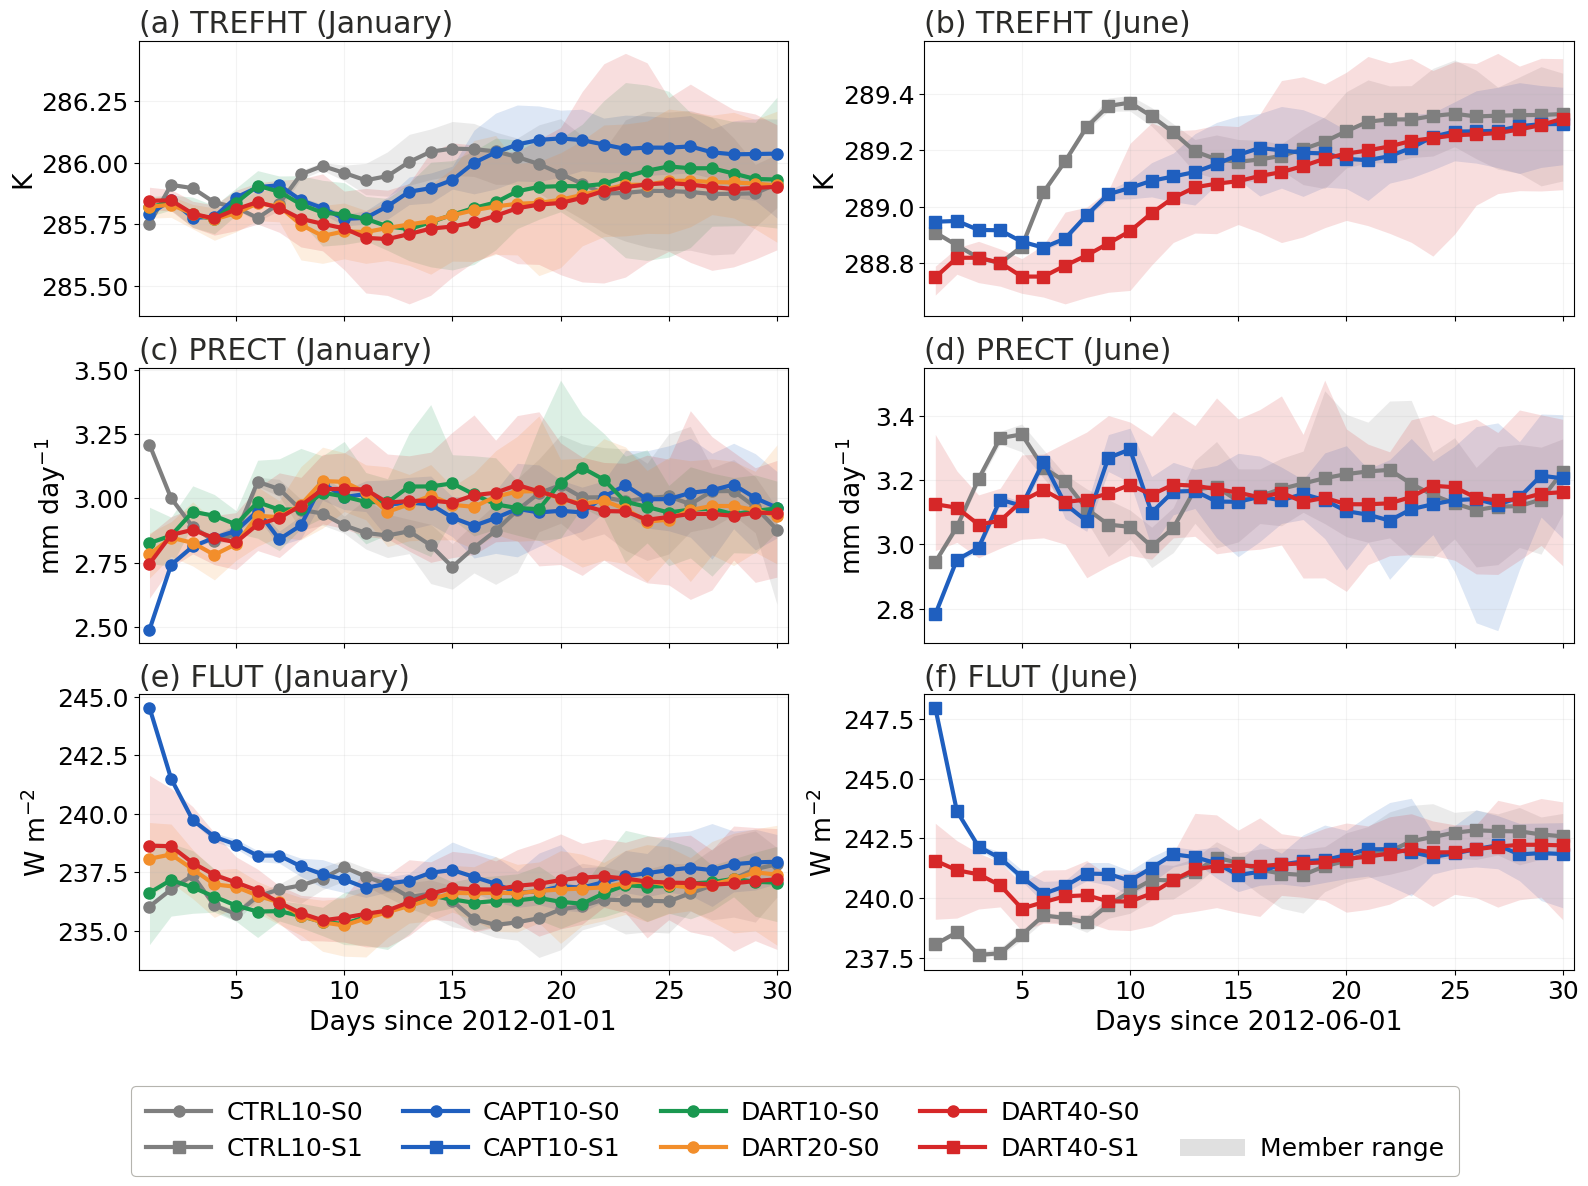

In [6]:
from util.forecast_daily_skill import plot_daily_timeseries, results_colors

def listing(items):  # "a, b, and c"
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + (", and " if len(items) > 2 else " and ") + items[-1]

# ---- Figure settings ----
FONTZ = 24  # base font size; panel titles 0.9x, axis labels 0.8x, ticks 0.75x, legend 0.85x, title 1x
FIGURE_TITLE = False  # False: no title above the panels
FIGURE_FORMAT = "pdf"  # "pdf" (vector) or "png"
FIGURE_DPI = 600  # png, and shaded areas inside the pdf
MAX_DAY = daily["max_day"]  # forecast days shown
TS_VARIABLES = ("TREFHT", "PRECT", "FLUT")  # rows (any of DAILY["variables"])
TS_SEASONS = tuple(CASES)  # columns (S0 left, S1 right); one figure with every season
TS_SEASON_NAMES = None  # panel labels "(a) TREFHT (January)"; None: month of each initial date; or {"S0": "...", "S1": "..."}
PANEL_SIZE = (8.0, 4.0)  # (width, height) of one panel, inches; wider for a longer time axis
XLABEL = None  # None: "Days since <initial date>" under each season column; or any text
# Experiment lines (ensemble mean): colors by experiment type, markers by season
TS_COLORS = COLORS  # from the performance figure: CTRL10 gray, CAPT10 blue, DART10 green, DART20 orange, DART40 red
TS_MARKERS = {"S0": "o", "S1": "s"}  # by season (S0 circles, S1 squares); seasons not listed use MARKER
LINE_WIDTH = 3.0
LINE_STYLES = {}  # per-experiment override, e.g. {"DART20-S0": "--"}; default solid "-"
MARKER = "o"  # types not in TS_MARKERS; None: no markers
MARKER_SIZE = 8
# Members
MEMBER_DISPLAY = "range"  # "range": shade member min-max; "members": every member, thin; "none"
MEMBER_ALPHA = 0.15  # opacity of the shading / member lines
# Observations
SHOW_OBS = False  # True: draw the observations (black) and add them to the legend
OBS_LINE = dict(color="black", lw=2.0, ls="-")  # observation line
OBS_NAME = None  # None: "Observations" (products go in the caption); or any text
GRID_ALPHA = 0.15  # 0: no grid
# Legend (below the panels)
LEGEND_FRAME = True
LEGEND_BY = "experiment"  # "experiment": CTRL10-S0, ..., one row per season; "type": CTRL10, ... once
LEGEND_NCOL = None  # None: one column per experiment type (S1 under S0, two rows); a number overrides it
LEGEND_EDGECOLOR = "#b5b4ae"
LEGEND_FONTZ = 0.75 * FONTZ  # legend font size, follows FONTZ; the box scales with it (None: 0.85 x FONTZ);
#   a legend wider than the figure is shrunk to fit

figure_dir = figure_root / "daily_performance"
figure_dir.mkdir(parents=True, exist_ok=True)

kind = lambda experiment: experiment.split("-")[0]  # DART20-S0 -> DART20
colors = results_colors(daily_results)
colors.update({e: TS_COLORS[kind(e)] for e in colors if kind(e) in TS_COLORS})
season_of = lambda experiment: experiment.rsplit("-", 1)[-1]  # DART20-S0 -> S0
markers = {e: TS_MARKERS[season_of(e)] for e in colors if season_of(e) in TS_MARKERS}
for region in REGIONS:
    fig = plot_daily_timeseries(
        daily_results, region, labels=labels, colors=colors, variables=TS_VARIABLES, seasons=TS_SEASONS,
        max_day=MAX_DAY, fontz=FONTZ, title=f"Hindcasts, {region}" if FIGURE_TITLE else "", panel_size=PANEL_SIZE,
        line_width=LINE_WIDTH, line_styles=LINE_STYLES, marker=MARKER, markers=markers, marker_size=MARKER_SIZE,
        member_display=MEMBER_DISPLAY, member_alpha=MEMBER_ALPHA, reference_line=OBS_LINE,
        reference_name=OBS_NAME, grid_alpha=GRID_ALPHA, legend_frame=LEGEND_FRAME, legend_ncol=LEGEND_NCOL,
        legend_edgecolor=LEGEND_EDGECOLOR, xlabel=XLABEL, legend_by=LEGEND_BY,
        season_names=TS_SEASON_NAMES, show_reference=SHOW_OBS, legend_fontz=LEGEND_FONTZ,
    )
    output = figure_dir / f"fig_daily_timeseries_{region}_{'_'.join(TS_SEASONS)}_fc.{FIGURE_FORMAT}"
    fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {output}")
    # Manuscript caption, built from the data and the settings above; saved next to the figure.
    long_names = {"PSL": "sea-level pressure (PSL; hPa)", "TREFHT": "2-m air temperature (TREFHT; K)",
                  "PRECT": "precipitation (PRECT; mm day\u207b\u00b9)",
                  "FLUT": "outgoing longwave radiation at the top of the atmosphere (FLUT; W m\u207b\u00b2)"}
    marker_names = {"o": "circles", "s": "squares", "^": "triangles", "D": "diamonds", "v": "inverted triangles"}
    color_names = {"#7f7f7f": "gray", "#1f5fbf": "blue", "#1a9850": "green", "#f28e2b": "orange",
                   "#d62728": "red", "#000000": "black"}
    
    starts = {s: pd.Timestamp(next(iter(next(iter(daily_results[s].values())).values())).day_start.values[0])
              for s in TS_SEASONS}
    months = {s: (TS_SEASON_NAMES or {}).get(s) or f"{starts[s]:%B}" for s in TS_SEASONS}
    members = {e: ds.sizes["member"] for s in TS_SEASONS for e, ds in daily_results[s][TS_VARIABLES[0]].items()}
    types = list(dict.fromkeys(kind(e) for e in members))
    ncol = len(TS_SEASONS)
    rows = listing(f"({', '.join(chr(97 + r * ncol + c) for c in range(ncol))}) {long_names.get(v, v)}"
                   for r, v in enumerate(TS_VARIABLES))
    columns = listing(f"{s} ({'boreal winter' if s == 'S0' else 'boreal summer'}) hindcasts initialized at {starts[s]:%H} UTC {starts[s].day} {starts[s]:%B %Y} "
                      f"({['left', 'right'][k] if len(TS_SEASONS) == 2 else months[s]} column)"
                      for k, s in enumerate(TS_SEASONS))
    first = {t_: next(e for e in members if kind(e) == t_) for t_ in types}
    present = {s: {kind(e) for e in daily_results[s][TS_VARIABLES[0]]} for s in TS_SEASONS}
    only = {s: [t_ for t_ in types if t_ in present[s] and all(t_ not in present[o] for o in TS_SEASONS if o != s)]
            for s in TS_SEASONS} if len(TS_SEASONS) > 1 else {s: [] for s in TS_SEASONS}  # e.g. DART10, DART20: S0
    refs = {v: next(iter(daily_results[TS_SEASONS[0]][v].values())).attrs.get("reference", "") for v in TS_VARIABLES}
    caption = (
        f"Global-mean daily {rows} in the first {MAX_DAY} forecast days of the {columns}. "
        "Lines show the ensemble mean of "
        + listing(f"{t_} ({color_names.get(colors[first[t_]].lower(), colors[first[t_]])})" for t_ in types)
        + "; the number in each name is the ensemble size"
        + (" (" + ", ".join(f"{t_}: {members[first[t_]]} members" for t_ in types
                            if int("".join(filter(str.isdigit, t_)) or 0) != members[first[t_]]) + ")"
           if any(int("".join(filter(str.isdigit, t_)) or 0) != members[first[t_]] for t_ in types) else "")
        + ". "
        + "".join(f"{listing(only[s])} {'was' if len(only[s]) == 1 else 'were'} run for {s} only. "
                  for s in TS_SEASONS if only[s])
        + (listing(f"{s} experiments are marked with {marker_names.get(TS_MARKERS.get(s, MARKER), 'markers')}"
                   for s in TS_SEASONS) + ". " if len(set(TS_MARKERS.get(s, MARKER) for s in TS_SEASONS)) > 1 else "")
        + {"range": "Shading spans the range (minimum to maximum) of the individual members' global means. ",
           "members": "Thin lines show the global means of the individual members. ", "none": ""}[MEMBER_DISPLAY]
        + ("The black line shows the observations ("
           + "; ".join(f"{p} for {', '.join(v for v in TS_VARIABLES if refs[v] == p)}" for p in dict.fromkeys(refs.values()))
           + "). " if SHOW_OBS else "")
        + "Day k is the 24-h mean ending k days after initialization, computed from the 6-hourly model output; "
        "global means are area-weighted (cosine of latitude) on the 1 x 1 degree grid."
    )
    output.with_suffix(".caption.txt").write_text(caption + "\n")
    print("[CAPTION]", caption)
    if not SHOW:
        plt.close(fig)

### Summary table


In [7]:
display(daily_summary.round(3))


,season,variable,units,experiment,members,region,reference,rmse_days1-3,bias_days1-3,crps_fair_days1-3,...,rmse_days4-10_subset_p05,rmse_days4-10_subset_p95,rmse_days1-3_vs_CTRL10_pct,rmse_days1-3_subset_vs_CTRL10_pct,rmse_days4-10_vs_CTRL10_pct,rmse_days4-10_subset_vs_CTRL10_pct,rmse_days1-3_vs_CAPT10_pct,rmse_days1-3_subset_vs_CAPT10_pct,rmse_days4-10_vs_CAPT10_pct,rmse_days4-10_subset_vs_CAPT10_pct
0,S0,PSL,hPa,CTRL10-S0,10,global,ERA5,9.983,-0.043,6.206,...,NaN,NaN,0.000,NaN,0.000,NaN,398.331,NaN,71.593,NaN
1,S0,PSL,hPa,CAPT10-S0,10,global,ERA5,2.003,0.064,1.131,...,NaN,NaN,-79.933,NaN,-41.723,NaN,0.000,NaN,0.000,NaN
2,S0,PSL,hPa,DART10-S0,10,global,ERA5,8.877,-8.343,6.417,...,NaN,NaN,-11.076,NaN,3.841,NaN,343.133,NaN,78.184,NaN
3,S0,PSL,hPa,DART20-S0,20,global,ERA5,8.647,-8.150,6.560,...,10.090,11.227,-13.379,-13.495,4.684,4.914,331.659,331.079,79.631,80.026
4,S0,PSL,hPa,DART40-S0,40,global,ERA5,8.017,-7.503,6.238,...,9.256,10.783,-19.689,-19.201,-2.186,-1.340,300.214,302.646,67.843,69.293
5,S0,TREFHT,K,CTRL10-S0,10,global,ERA5,3.748,0.122,2.097,...,NaN,NaN,0.000,NaN,0.000,NaN,94.855,NaN,36.022,NaN
6,S0,TREFHT,K,CAPT10-S0,10,global,ERA5,1.923,0.074,0.936,...,NaN,NaN,-48.680,NaN,-26.482,NaN,0.000,NaN,0.000,NaN
7,S0,TREFHT,K,DART10-S0,10,global,ERA5,2.399,0.086,1.019,...,NaN,NaN,-35.984,NaN,-23.596,NaN,24.738,NaN,3.926,NaN
8,S0,TREFHT,K,DART20-S0,20,global,ERA5,2.313,0.083,1.006,...,3.275,3.372,-38.293,-38.213,-21.827,-21.395,20.239,20.394,6.332,6.919
9,S0,TREFHT,K,DART40-S0,40,global,ERA5,2.313,0.097,1.005,...,3.218,3.323,-38.294,-38.212,-23.122,-22.708,20.237,20.397,4.571,5.134


## 5. Initial shock (6-hourly)

### Driver: read, process, and save data

The native 6-hourly output after initialization (`SHOCK` settings, `SHOCK_DAYS`, `SETTLED_DAYS`); reuse valid caches or build missing ones, then compute and save the shock summary.


In [8]:
from util.forecast_ensemble_ts import read_or_process_ensemble_ts, shock_summary_table, validate_mode
from util.forecast_daily_skill import check_temporal_semantics

shock = validate_mode("shock", {"shock": SHOCK})
print(f"initial shock: {shock}")
if VALIDATE_SEMANTICS:  # first experiment of each season
    for season, experiments in cases.items():
        first = registries[season][experiments[0]]
        display(check_temporal_semantics(first, shock["variables"], first["period"], frequency=shock["frequency"]))

shock_results, shock_registries, failures = read_or_process_ensemble_ts(
    cases, shock["variables"], data_root=INPUT_DATA_ROOT, cache_dir=data_dir,
    frequency=shock["frequency"], regions=REGIONS, landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc",
    reference_root=OBSERVATION_ROOT, references=shock["references"],
    max_members=MAX_MEMBERS, force_compute=FORCE_COMPUTE,
)
for season, variable, experiment, error in failures:
    print(f"[SKIPPED] {season} {variable} {experiment}: {error}")
shock_summary = shock_summary_table(shock_results, shock_days=SHOCK_DAYS, settled_days=SETTLED_DAYS,
                                    tolerance=TOLERANCE)
for season in cases:
    table_path = data_dir / f"summary_{season}_fc_shock.csv"
    shock_summary[shock_summary["season"] == season].to_csv(table_path, index=False)
    print(f"[TABLE] {table_path}")


initial shock: {'references': {}, 'member_display': 'members', 'zoom_days': 30, 'plots': ('tendency',), 'core': ('CTRL10', 'CAPT10', 'DART10'), 'kind': 'shock', 'frequency': '6hourly', 'variables': ('PSL', 'TREFHT', 'PRECT', 'FLUT')}


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,PRECT,time: mean,m/s,0.0,6.0,width-weighted mean of interval means,ok
3,FLUT,time: mean,W/m2,0.0,6.0,width-weighted mean of interval means,ok


,variable,cell_methods,units,first_record_width_h,record_width_h,aggregation,check
0,PSL,time: point,Pa,0.0,6.0,trapezoid of instantaneous values,ok
1,TREFHT,time: mean,K,0.0,6.0,width-weighted mean of interval means,ok
2,PRECT,time: mean,m/s,0.0,6.0,width-weighted mean of interval means,ok
3,FLUT,time: mean,W/m2,0.0,6.0,width-weighted mean of interval means,ok


[REUSE] CTRL10-S0_PSL_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CAPT10-S0_PSL_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART10-S0_PSL_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART20-S0_PSL_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART40-S0_PSL_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CTRL10-S0_TREFHT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CAPT10-S0_TREFHT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART10-S0_TREFHT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART20-S0_TREFHT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART40-S0_TREFHT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CTRL10-S0_PRECT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CAPT10-S0_PRECT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART10-S0_PRECT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART20-S0_PRECT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] DART40-S0_PRECT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CTRL10-S0_FLUT_6hourly_201201-201202_ensemble_ts.nc
[REUSE] CAPT10-S0_FLUT_6hourly

### Figures

The tendency figure (`(a) |dX/dt| (PSL)`, `(b) Normalized |dX/dt| (PSL)`, ...; core experiments solid, others dashed, the reference dotted) and the shock-summary bars; font size, title, and dpi are set at the top of the cell.


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_tendency_global_S0_fc_shock.pdf
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_tendency_global_S1_fc_shock.pdf
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_summary_global_S0_fc_shock.pdf
[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_summary_global_S1_fc_shock.pdf


[PosixPath('/compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_summary_global_S0_fc_shock.pdf'),
 PosixPath('/compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_atm_ensemble_ts/shock/fig_shock_summary_global_S1_fc_shock.pdf')]

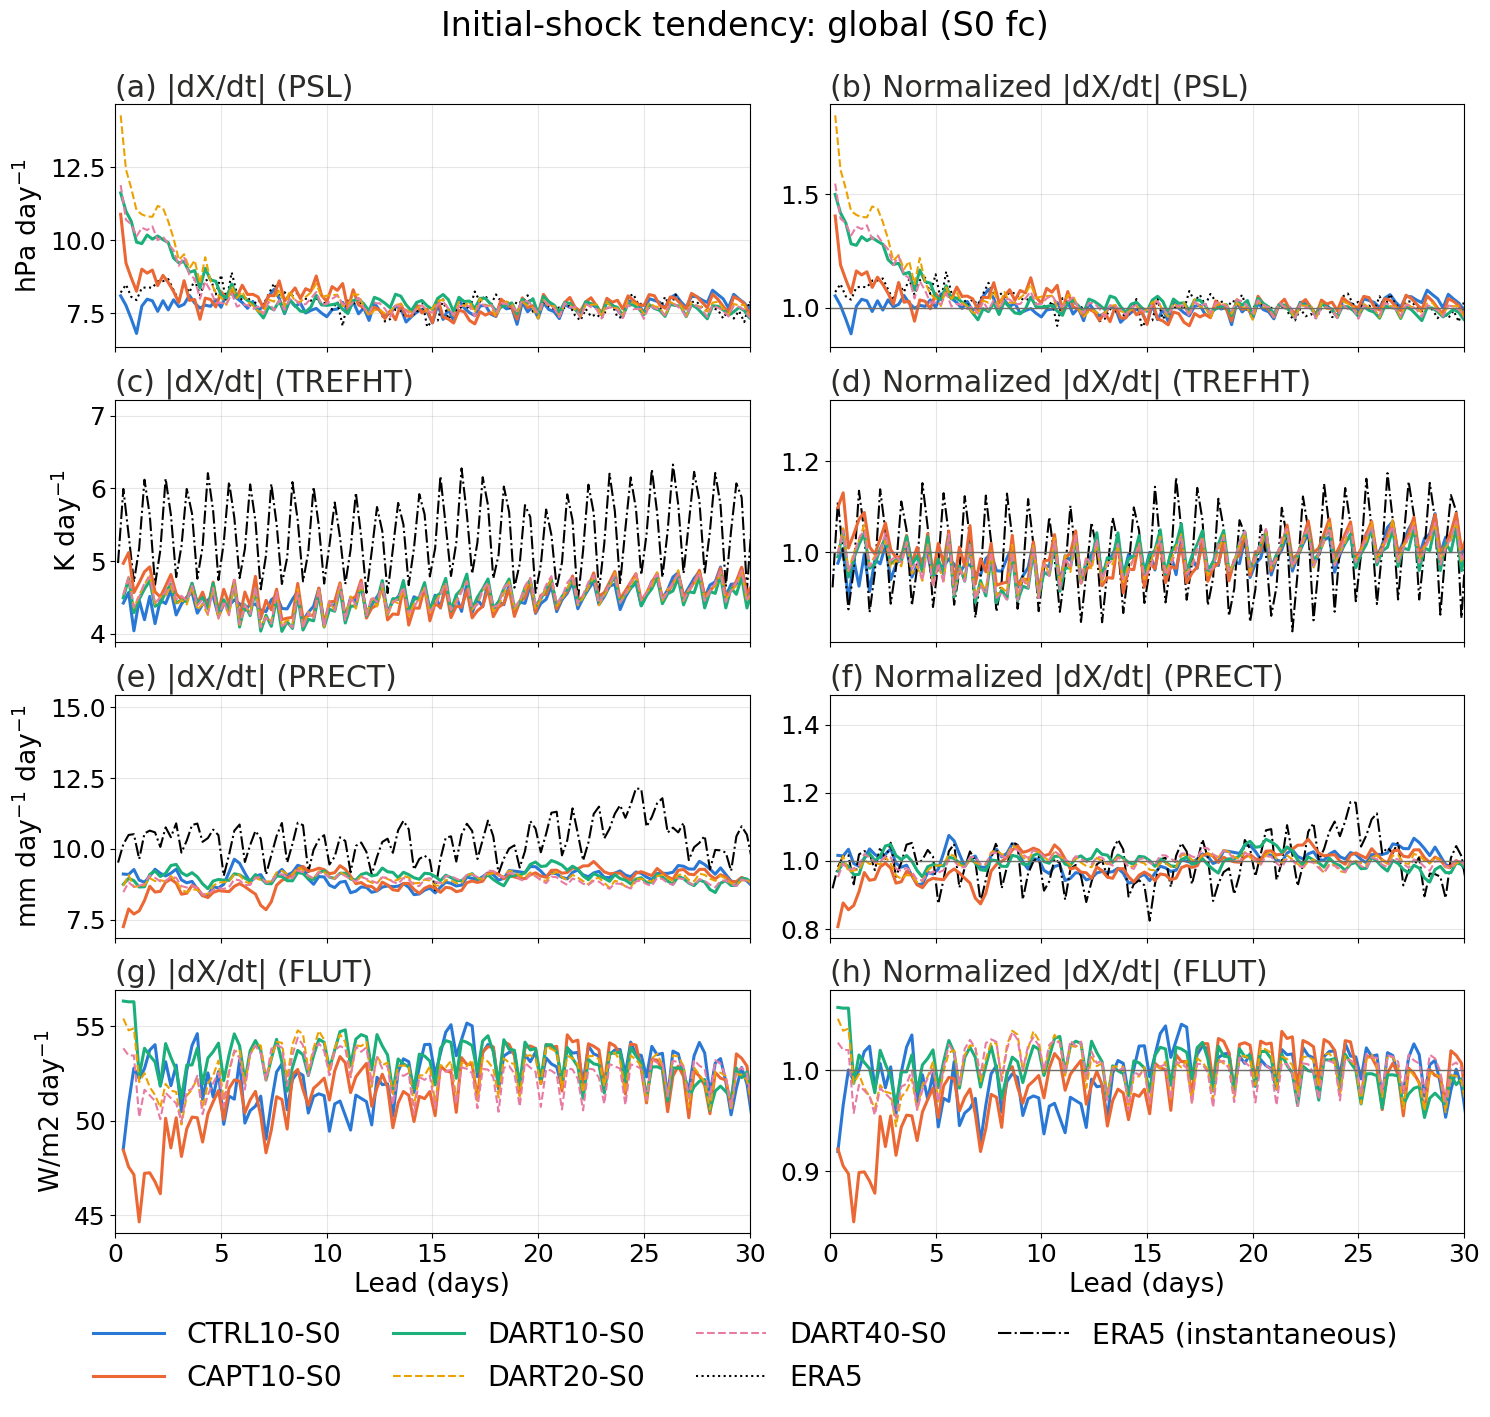

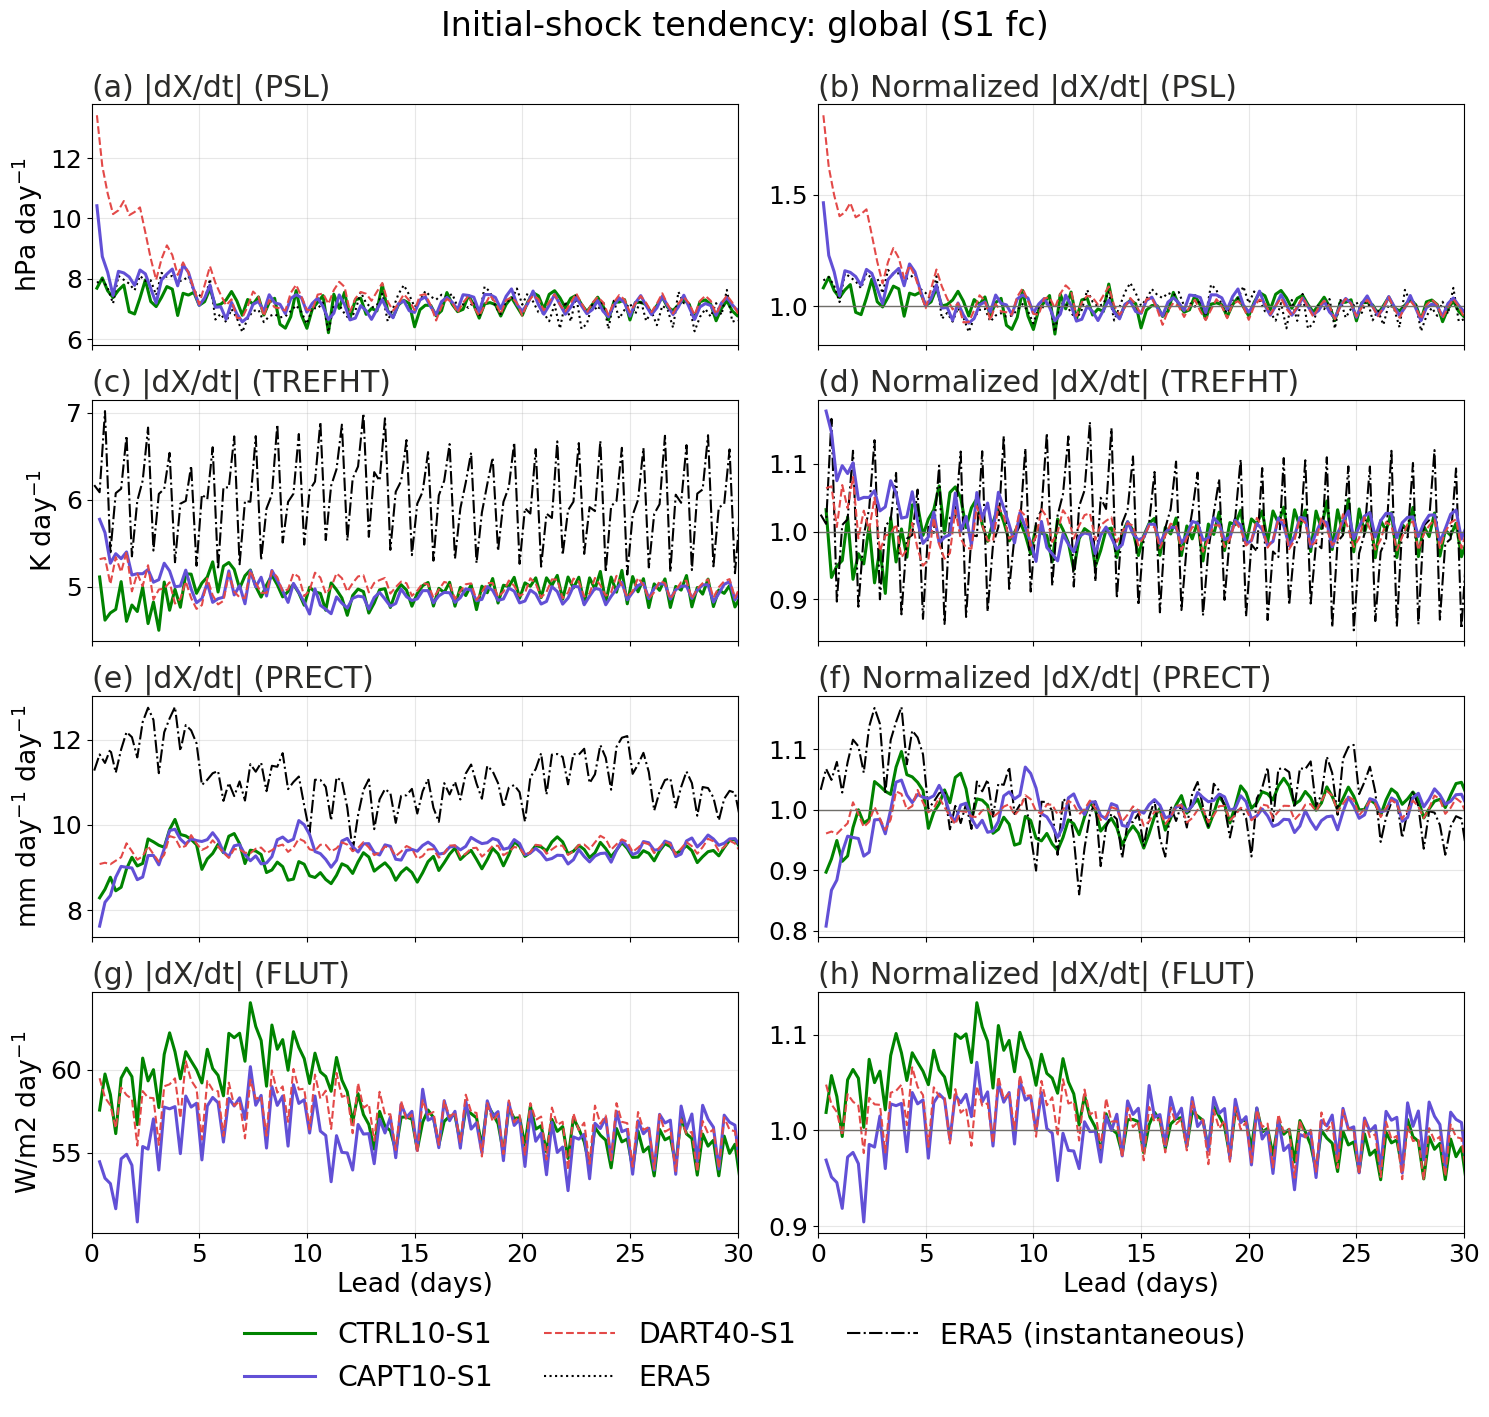

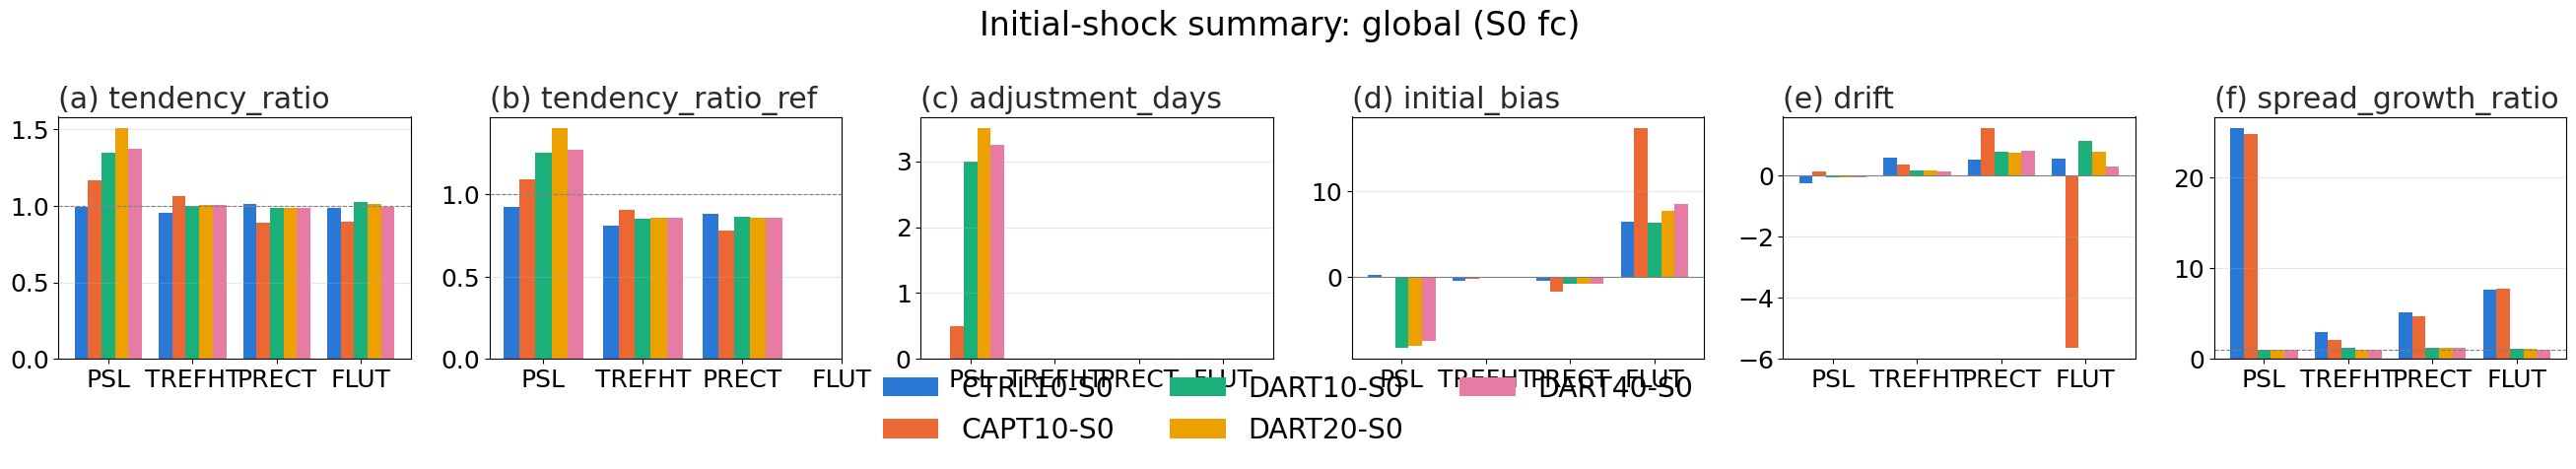

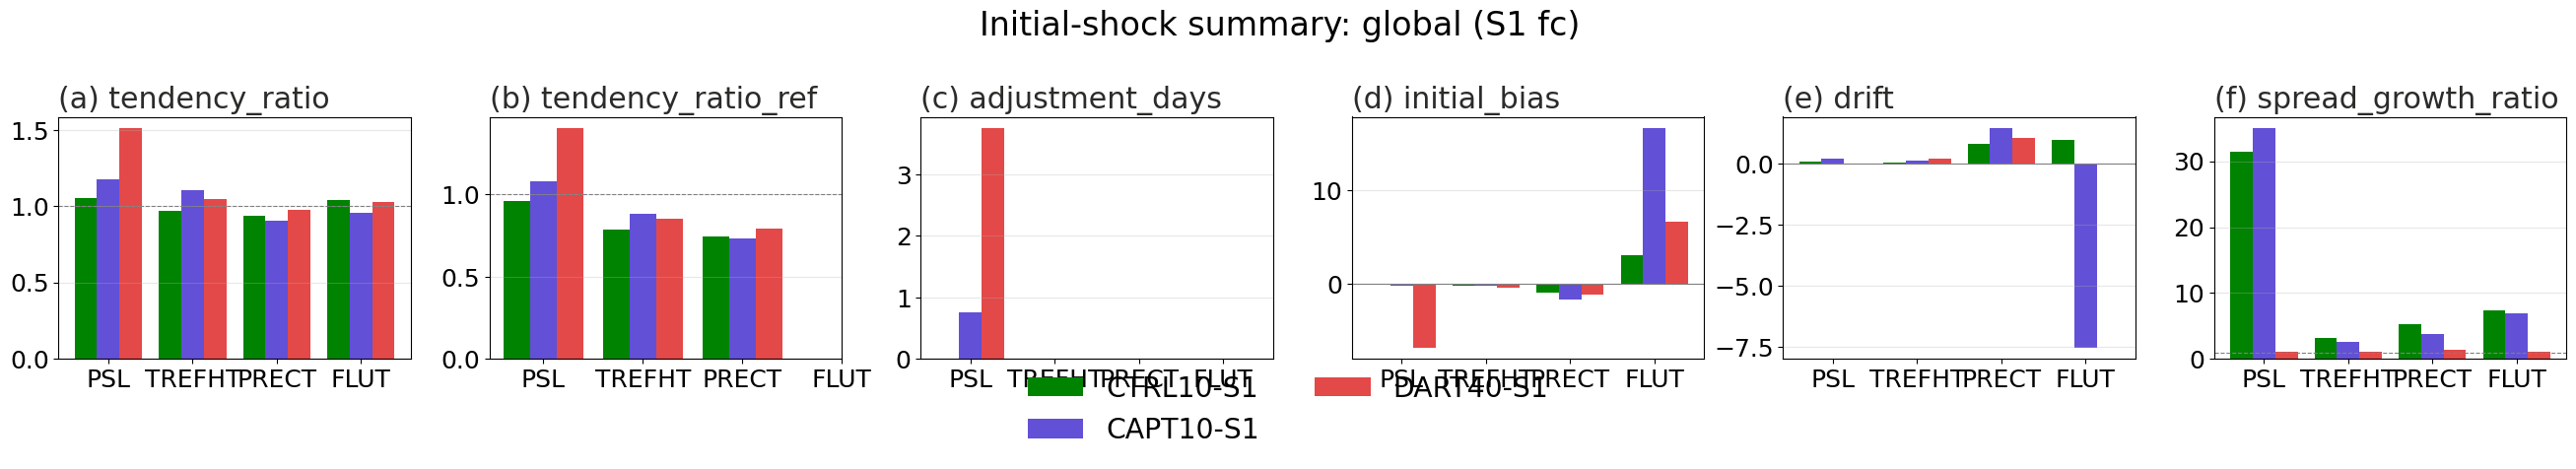

In [9]:
from util.forecast_ensemble_ts import plot_ensemble_ts_figures, plot_shock_summary_figures, results_colors

# ---- Figure settings ----
FONTZ = 24  # base font size; panel titles 0.9x, axis labels 0.8x, ticks 0.75x, legend 0.85x, title 1x
FIGURE_TITLE = True  # False: no title above the panels (details go in the caption)
FIGURE_FORMAT = "pdf"  # "pdf" (vector) or "png"
FIGURE_DPI = 200  # png, and shaded areas inside the pdf
ZOOM_DAYS = shock["zoom_days"]  # lead days shown
CORE = shock["core"]  # solid lines; other experiments dashed (sensitivity)

figure_dir = figure_root / "shock"
colors = results_colors(shock_results)
plot_ensemble_ts_figures(
    shock_results, shock_registries, regions=REGIONS, figure_dir=figure_dir, tag="shock", plots=shock["plots"],
    colors=colors, core=CORE, settled_days=SETTLED_DAYS, zoom_days=ZOOM_DAYS,
    member_display=shock["member_display"], dpi=FIGURE_DPI, show=SHOW, fontz=FONTZ, title=FIGURE_TITLE,
    fmt=FIGURE_FORMAT,
)
plot_shock_summary_figures(shock_summary, figure_dir=figure_dir, tag="shock", colors=colors,
                           dpi=FIGURE_DPI, show=SHOW, fontz=FONTZ, title=FIGURE_TITLE, fmt=FIGURE_FORMAT)

### Summary table


In [10]:
display(shock_summary.round(3))


,season,experiment,label,variable,region,units,tendency_ratio,tendency_ratio_ref,adjustment_days,initial_bias,drift,spread_growth_ratio
0,S0,CTRL10-S0,CTRL10-S0,PSL,global,hPa,0.995,0.921,0.00,0.175,-0.255,25.407
1,S0,CAPT10-S0,CAPT10-S0,PSL,global,hPa,1.167,1.089,0.50,-0.065,0.132,24.827
2,S0,DART10-S0,DART10-S0,PSL,global,hPa,1.346,1.256,3.00,-8.275,-0.071,1.051
3,S0,DART20-S0,DART20-S0,PSL,global,hPa,1.508,1.402,3.50,-8.082,-0.070,1.003
4,S0,DART40-S0,DART40-S0,PSL,global,hPa,1.375,1.272,3.25,-7.441,-0.064,1.006
5,S0,CTRL10-S0,CTRL10-S0,TREFHT,global,K,0.956,0.813,0.00,-0.413,0.577,2.905
6,S0,CAPT10-S0,CAPT10-S0,TREFHT,global,K,1.064,0.903,0.00,-0.260,0.363,2.100
7,S0,DART10-S0,DART10-S0,TREFHT,global,K,0.999,0.851,0.00,-0.056,0.152,1.203
8,S0,DART20-S0,DART20-S0,TREFHT,global,K,1.009,0.861,0.00,-0.062,0.146,1.029
9,S0,DART40-S0,DART40-S0,TREFHT,global,K,1.005,0.860,0.00,-0.021,0.123,1.038


## Notes: definitions

**Daily metrics** (per forecast day, over the region's gridpoints that the reference covers; cos-latitude weights $w$; ensemble size $N$):

| Output | Definition |
|---|---|
| `rmse` | $\sqrt{\langle(\bar X - O)^2\rangle_w}$, RMSE of the daily ensemble mean $\bar X$ |
| `bias` | $\langle \bar X - O\rangle_w$ (saved, not plotted) |
| `spread` | RMS ensemble spread $S = \sqrt{\langle\sigma^2\rangle_w}$, $\sigma^2$ the unbiased member variance |
| `spread_corr`, `spread_ratio` | $S\sqrt{(N+1)/N}$ and its ratio to RMSE; 1 is the expectation for a reliable $N$-member ensemble (`spread_ratio_raw` = $S$/RMSE) |
| `crps_fair` | fair CRPS, $\frac{1}{N}\sum_i|x_i-O| - \frac{1}{2N(N-1)}\sum_{i,j}|x_i-x_j|$, area mean (ensemble-size adjusted; table only) |
| `member_mean`, `reference_mean` | regional mean $\langle x_i\rangle_w$ of each member and $\langle O\rangle_w$ of the reference (field time series; ensemble mean minus reference = `bias`) |
| `rmse_subset`, `spread_ratio_subset` | the same for `n_subsets` random `subset_size`-member subsets of larger ensembles |

The summary table gives, per experiment and variable: RMSE, bias, and fair CRPS over days 1-3 and 4-10; mean spread/RMSE over days 1-10; subset RMSE (mean and 5-95%); and % RMSE change relative to the season's CTRL10 and CAPT10.

**Daily references.** PSL and TREFHT: ERA5 6-hourly samples, trapezoid-averaged over each 24-hour bin; PRECT: GPCP daily (GPM IMERG daily and ERA5 6-hourly as sensitivity choices); FLUT: NOAA interpolated OLR daily. For 00 UTC starts the bins coincide with calendar days; otherwise daily references are overlap-weighted onto the bins. GPCP covers the globe, so the four-variable figure can use `global`; IMERG covers only about 60S-60N, so use `60S-60N` with GPM.

**Model daily files.** The hindcast post output stores 00Z-24Z daily means in `ts/daily_mean` (00Z states are in `ts/daily_00z`). This notebook still builds its daily values from the 6-hourly output, so that the bins follow forecast lead (also for non-00Z starts) and PSL uses the same trapezoid as its ERA5 reference. The validation step compares the lead-bin means with `ts/daily_mean`. Interval means (TREFHT, PRECT) agree to rounding. PSL differs by design: `daily_mean` averages the 00/06/12/18Z states, while the trapezoid also uses the 24 h state. FLUT differs on day 1 only, by up to ~5 W m$^{-2}$ locally, because `daily_mean` FLUT comes from the EAM h1 daily stream, whose first-day average treats the initial step differently from the 6-hourly stream.

**Shock mode.** Records are placed at their lead time (interval midpoint for means, interval end for instantaneous values) and verified against ERA5 6-hourly samples averaged over the same intervals. Diagnostics: regional mean $|dX/dt|$ per member (for interval means starting at the first mean, skipping the lead-0 snapshot), ensemble spread, and the reference tendency. Summary: `tendency_ratio` ($|dX/dt|$ over days 0-`SHOCK_DAYS` / over `SETTLED_DAYS`), `tendency_ratio_ref` (/ reference), `adjustment_days`, `initial_bias`, `drift`, and `spread_growth_ratio` (spread at the end of the shock window / at lead 0; not a spread/RMSE ratio).

Caches: daily metrics `daily_skill/<experiment>_<variable>_<period>_daily_skill.nc` record the product, cache version, aggregation, spread definition, reference, ensemble size, and subset settings, and are rebuilt when any changes; shock caches `<experiment>_<variable>_<frequency>_<period>_ensemble_ts.nc` are separate.